# 2.1 Image processing tools
Image processing encompasses a number of techniques to improve the overall quality of an image (image smoothing, enhancement, etc.). Before going into those techniques in depth, it is useful to understand some basic concepts:
- Image histograms
- Brightness and contrast
- Binarization
- Look-up tables
- Convolutions
- Image resizing (upsampling and downsampling).

Next sections introduce those concepts in the context of a real problem.


## Problem context - Number-plate recognition

<img src="https://raw.githubusercontent.com/jotaraul/cv_hub/refs/heads/main/image_processing/images/access_system.png" width="400">


Recently, the University of Málaga (UMA) is having trouble with private parking access. Someone has hacked their access system, so cars without previous authorization are parking there.

UMA asked computer vision students for help to implement some more secure methods that have to be included in a new security system.

They provided some images of unauthorized plates to ease the software development: `car_plate_1.jpg`, `car_plate_2.jpg` and `car_plate_3.jpg`.

In [ ]:
# In case of using Google Colab, mount Google Drive
try:
    from google.colab import drive
    drive.mount('/content/drive')
    # If your notebook and images are in your Drive, change directory accordingly:
    %cd '/content/drive/MyDrive/Colab Notebooks/uma_cv_2027/Chapter 02. Image processing'
except ImportError:
    pass

import numpy as np
import cv2
import matplotlib.pyplot as plt
import matplotlib
from ipywidgets import interactive, fixed, widgets
matplotlib.rcParams['figure.figsize'] = (15.0, 15.0)

images_path = './images/'

Mounted at /content/drive
/content/drive/MyDrive/Colab Notebooks/uma_cv_2027/Chapter 02. Image processing


## 2.1.1 Image histograms

And there we go! We are excited with the idea of developing a software to help UMA. For that, they provided us with a list of concepts and techniques that we have to master in order to design a successful plate recognition system.

The first one is such of **histogram**:

- A representation of the frequency of each color intensity appearing in the image.
- It is built by iterating over all the pixels in the image while counting the occurrence of each color. *Note that a RGB image has 3 histograms, one per channel.*
- It provides statistical information of the intensity distribution, like the image brightness or contrast.

The concepts of **brightness** and **contrast** are specially relevant for image processing:
- **brightness**: average intensity of image pixels, so dark images have a low brightness, while lighter ones have a high brightness. It is computed as:
$$\overline{i}=\sum_{i=0}^{255}i \, h(i)$$
- **contrast**: standard deviation of the pixel intensities computed as the square distance of the intensities from the average, that is, a measure of the quality of the image given its usage of all the possible color intensities in the histogram:
$$\sigma = \sqrt{\sum_{i=0}^{255}(i-\overline{i})^2 \, h(i)}$$

Typically, a high quality image have a medium brightness and a high contrast.

The following code illustrates these first concepts with a few examples!

*Interesting functions:*
- [`cv2.imread()`](https://www.geeksforgeeks.org/python-opencv-cv2-imread-method/) *function for reading images in OpenCV.*
- [`plt.subplot()`](https://matplotlib.org/api/_as_gen/matplotlib.pyplot.subplot.html) *this method from matplotlib creates a grid of subfigures with a given number of rows and columns.*
- [`plt.hist()`](https://matplotlib.org/3.3.1/api/_as_gen/matplotlib.pyplot.hist.html) *function that computes and draws the histogram of an array.  [`numpy.ravel()`](https://docs.scipy.org/doc/numpy/reference/generated/numpy.ravel.html) is a good helper here, since it converts a n-dimensional array into a flattened 1D array.*
- [`plt.imshow()`](https://matplotlib.org/3.3.2/api/_as_gen/matplotlib.pyplot.imshow.html) *matplotlib function for displaying images. If the image is grayscale you should use the parameter `cmap='gray'`.*

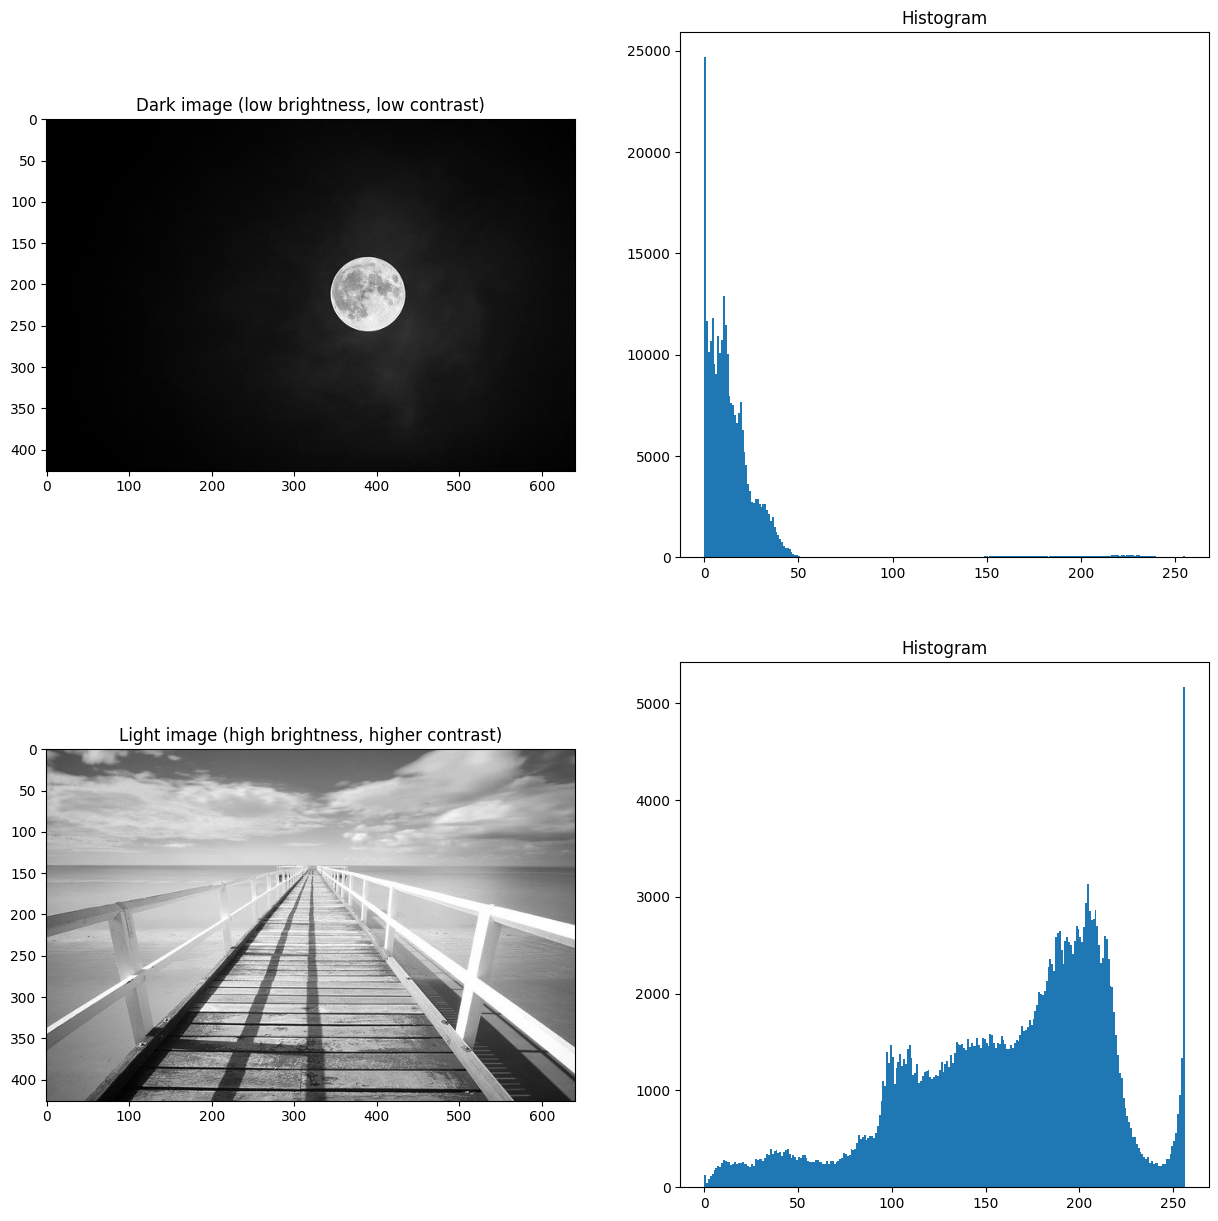

In [ ]:
# Read dark image and show it
image = cv2.imread(images_path + 'landscape_1.jpg',cv2.IMREAD_GRAYSCALE)
plt.subplot(2,2,1)
plt.title("Dark image (low brightness, low contrast)")
# plt.xticks([]), plt.yticks([])  # this option hides tick values on X and Y axis
plt.imshow(image, cmap='gray')

# Now, show its histogram
plt.subplot(2,2,2)
plt.title("Histogram")
plt.hist(image.ravel(), 256, range=[0, 255]) # ravel() returns a 1-D array, containing the elements of image

# Read light image and show it
image = cv2.imread(images_path + 'landscape_2.jpg',cv2.IMREAD_GRAYSCALE)
plt.subplot(2,2,3)
plt.title("Light image (high brightness, higher contrast)")
plt.imshow(image, cmap='gray')

# Now, its histogram
plt.subplot(2,2,4)
plt.title("Histogram")
plt.hist(image.ravel(), 256, range=[0, 256]) # ravel() returns a 1-D array, containing the elements of image
plt.show()

## 2.1.2 Binarization

One of the utilities of histograms is the fit of thresholds for **binarization**. Binarization consists of assigning the "0" or black value to the pixels having an intensity value under a given threshold (`th`), and "1" or white value to those having an intensity over it. Formally:

$$
binarized(i,j)=\left\{\begin{matrix}
0 & \text{if } intensity(i,j) < th\\
1 & \text{otherwise}
\end{matrix}\right. \ \ \ \forall i \in [0 \dots n\_rows-1], \forall j \in [0 \dots n\_cols-1]
$$

In our context, binarization can be a great tool for separating characters appearing on the plate (with a dark color) from the rest of the plate (with a lighter one). This will remove unnecessary information within the image. So let's implement it!

### **<span style="color:green"><b><i>ASSIGNMENT 1: Cropping an image</i></b></span>**

Read the image `car_plate_1.jpg` as grayscale and crop it to a rectangle (approximately) containing the plate.

*Hint: to crop an image you can use numpy array slicing.*

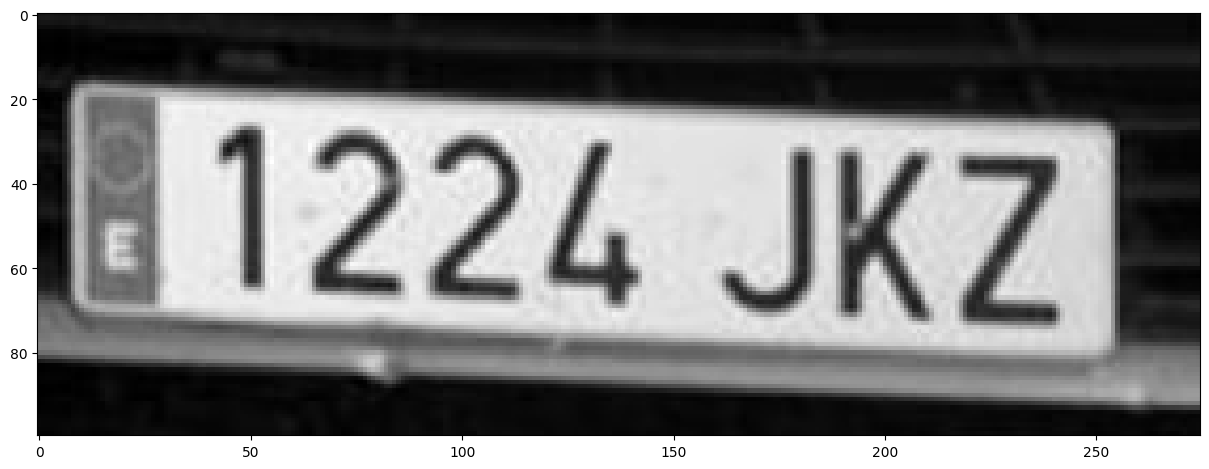

In [ ]:
# * ASSIGNMENT 1 *
# Load the image, crop it around the car plate and show it
# Write your code here!

image = cv2.imread(images_path + 'car_plate_1.jpg', cv2.IMREAD_GRAYSCALE) # Load the image
image_cropped = image[300:400, 200:475] # crop it
plt.imshow(image_cropped, cmap='gray') # show it!
plt.show()

<font color='blue'>**Expected output:**  </font>

![image.png](https://raw.githubusercontent.com/jotaraul/cv_hub/refs/heads/main/image_processing/images/expected_crop.png)


Now, we are going to use the first concept we learned, **histograms**, to see if the image is easily binarizable. To fulfill this condition, the intensity of the pixels in the image must be roughly grouped around two different values.

### **<span style="color:green"><b><i>ASSIGNMENT 2: Showing a histogram</i></b></span>**

Show the histogram of `image_cropped`.

*Tip: [plot histogram using matplotlib](https://matplotlib.org/3.2.0/api/_as_gen/matplotlib.pyplot.hist.html), bins and range parameters are very important! Also recall the `ravel()` funciton*

/tmp/ipykernel_1304/2486459271.py:4: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(image_cropped.ravel(), 256, [0, 255])


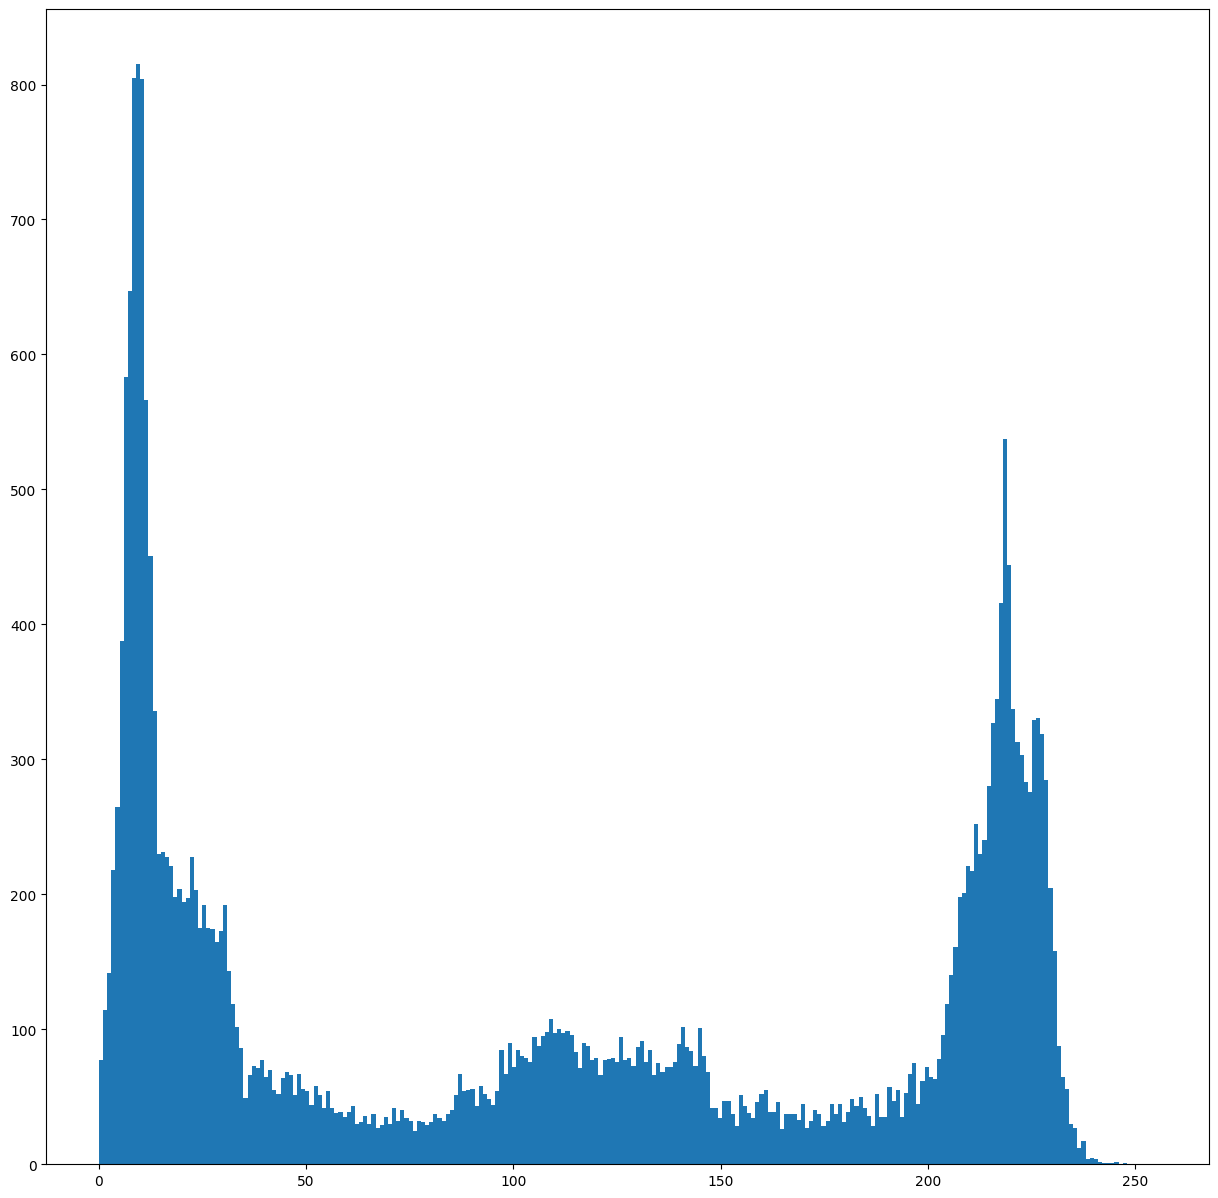

In [ ]:
# ** ASSIGNMENT 2 **
# Compute the image histogram and show it
# Write your code here!
plt.hist(image_cropped.ravel(), 256, [0, 255])

None # Compute the histogram and show it
plt.show()

<font color='blue'>**Expected output:**  </font>

![image.png](https://raw.githubusercontent.com/jotaraul/cv_hub/refs/heads/main/image_processing/images/expected_hist.png)


### <font color="blue"><b><i>Thinking about it (1)</i></b></font>

**Answer the following questions** about the obtained results:

- According to your (growing) expertise, could we correctly binarize this image?

    <p style="margin: 4px 0px 6px 5px; color:blue"><i>Your answer here!</i></p>

- Which threshold should we use?

    <p style="margin: 4px 0px 6px 5px; color:blue"><i>Your answer here!</i></p>

### **<span style="color:green"><b><i>ASSIGNMENT 3: Binarizing an image. Exciting, isn't it?</i></b></span>**

Now that we have some cues about how to binarize an image, let's take a look through [OpenCV documentation](https://docs.opencv.org/master/d7/d4d/tutorial_py_thresholding.html) to develop it.

Implement a function that:
- takes a gray image and a threshold as inputs,
- binarizes the image,
- and displays it!

*Hint: Notice that some OpenCV functions return a variable called **ret** as their first output, whose content depends on the function itself.*

In [ ]:
# ** ASSIGNMENT 3 **
# Implement a function that binarizes an image and displays it
def binarize(image,threshold):
    """ Binarizes an input image and returns it.

        Args:
            image: Input image to be binarized
            threshold: Pixels with intensity values under this parameters
                    are set to 0 (black), and those over it to 255 (white).

        Returns:
            image_binarized: Binarized image
    """
    ret,image_binarized = cv2.threshold(image, threshold, 255, cv2.THRESH_BINARY)
    plt.figure(figsize=(6,6))
    plt.imshow(image_binarized, cmap="gray")
    plt.title('Binarized image')
    plt.show()
    return image_binarized

#### Extra! interacting with code

Jupyter has some interesting methods that allow interaction with our code, and we are going to leverage them throughout the course. Concretely, we will use the [interaction function](https://ipywidgets.readthedocs.io/en/latest/examples/Using%20Interact.html).

To play a bit with it, move the slider below to change the threshold value when calling the `binarize()` function.

In [ ]:
# Interact with the threshold value
interactive(binarize, image=fixed(image_cropped), threshold=(0, 255, 25))

interactive(children=(IntSlider(value=125, description='threshold', max=255, step=25), Output()), _dom_classes…

<font color='blue'>**Expected output:**  </font>

![image.png](https://raw.githubusercontent.com/jotaraul/cv_hub/refs/heads/main/image_processing/images/expected_binary.png)


## 2.1.3 Look-up Tables (LUTs)

Another basic, widely used technique for image processing is such of **Look-up Tables (LUTs)**. A LUT is a table to look up the output intensity for each input one. That is, it defines a mapping between input intensity values and output ones.

Note that if working with color (e.g. RGB) images, a LUT has to be defined for each color channel.

LUTs are extremely useful for modifying the brightness and contrast of images, that is, for adapting their histograms according to our needs. Some examples about the possibilities that LUTs offer are shown below (the x-axes represent input intensity values, while y-axes represent output ones):

<img src="https://raw.githubusercontent.com/jotaraul/cv_hub/refs/heads/main/image_processing/images/bright_contrast.png" width="1000"/>

For example, the figure below shows the result of applying a LUT where the pixels with intensities from 0 to 50 are assigned to 0 (black), and those from 200 to 255 are assigned to 255 (white). Pixels with values in between are assigned to values from 1 to 254. The histogram of the resultant image is also shown:

<img src="https://raw.githubusercontent.com/jotaraul/cv_hub/refs/heads/main/image_processing/images/result_lut.png" width="500"/>

Regarding our plate recognition problem, by doing this we remove noisy intensity values around black and white, obtaining a more *clean* image (see the resultant histogram). And, of course, we want to try it!

### **<span style="color:green"><b><i>ASSIGNMENT 4a: Things get serious, implementing a LUT!</i></b></span>**

Implement the `lut_chart()` function to:
- take a gray image and a look-up table (256-length array),
- display a chart showing differences between the initial image and the resultant one after applying the LUT. *Tip: [how to create subplots in Python](https://matplotlib.org/3.1.1/api/_as_gen/matplotlib.pyplot.subplot.html)*

*Interesting functions:*
- [cv2.LUT()](https://docs.opencv.org/master/d2/de8/group__core__array.html#gab55b8d062b7f5587720ede032d34156f): *function that  performs a look-up table transform of an array of arbitrary dimensions.*

In [ ]:
# ** ASSIGNMENT 4a **
# Implement a function that takes a gray image and applies a LUT to it. This must show a 2x2 plot with
# -- input image
# -- resultant image
# -- employed LUT
# -- histogram of the resultant image
def lut_chart(image, lut):
    """ Applies a LUT to an image and shows the result.

        Args:
            image: Input image to be modified.
            lut: a 256 elements array representing a LUT, where
                indices index input values, and their content the
                output ones.
    """


    # Apply LUT
    im_lut = cv2.LUT(image, lut)

    # Show the initial image
    plt.figure(1)
    plt.figure(figsize=(10,10))
    plt.subplot(2, 2, 1)
    plt.imshow(image, cmap = "gray")
    plt.title('Original image')

    # Show the resultant one
    plt.subplot(2, 2, 2)
    plt.imshow(im_lut, cmap = "gray")
    plt.title('LUT applied')

    # Plot the used LUT
    plt.subplot(2,2,3)
    plt.title('LUT')
    plt.plot(lut) # Hint: np.arange() can be useful as first argument to this function

    # And finally, the resultant histogram
    plt.subplot(2, 2, 4)
    plt.hist(im_lut.ravel(), 256, range=[0, 256])
    plt.title('Histogram')
    plt.show()


### **<span style="color:green"><b><i>ASSIGNMENT 4b: Applying our amazing function</i></b></span>**

Finally, let's try our `lut_chart()` function with different look-up tables. Try to play with brightness and contrast in order to get an enhanced image. For that:

1. Create a look-up table.
2. Call our function with it as second argument.

You can repeat the previous steps playing with different look-up tables and showing the results using *subplots*.

*Hint: An easy way to create a LUT could be:*
1. Create an *identity LUT* with numbers from 0 up to 255 with [`numpy.arange()`](https://docs.scipy.org/doc/numpy/reference/generated/numpy.arange.html) (this function returns evenly spaced values within a given interval). If you use this directly as LUT, the pixels in the output will have the same intensity value as in the input. Try it!
2. Modify such LUT using [`numpy.clip()`](https://docs.scipy.org/doc/numpy/reference/generated/numpy.clip.html). For that you could call it as `lut = np.clip((lut-a)*b,0,255)`.

<Figure size 1500x1500 with 0 Axes>

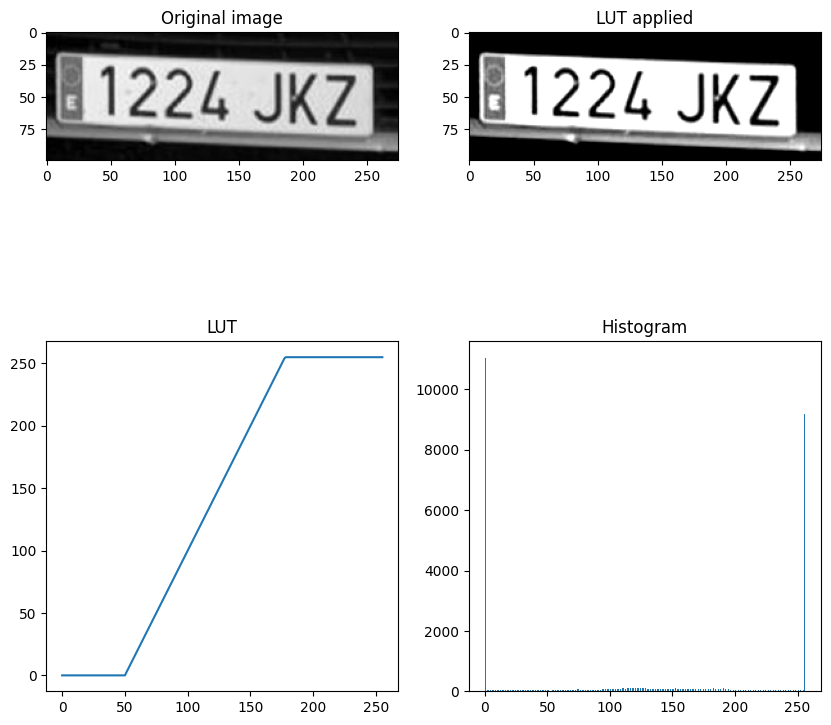

In [ ]:
# ASSIGNMENT 4b
# Create the LUT array (have a look at numpy.arange and numpy.clip functions)
lut = np.arange(0, 256)
a = 50
b = 2
lut = np.clip((lut-a)*b, 0, 255)

# print(image_cropped)

# Execute our function on the cropped car plate image
lut_chart(image_cropped,lut)

<font color='blue'>**Expected output:**  </font>

![image.png](https://raw.githubusercontent.com/jotaraul/cv_hub/refs/heads/main/image_processing/images/expected_lut.png)


## 2.1.4 Convolutions

A 2D convolution, represented by the $\oplus$ symbol, is a fundamental tool in numerous image processing techniques (e.g. image smoothing, edge detection, etc.). Concretely, this mathematical operation is useful when implementing operators whose output pixel values are linear combinations of input ones.

There are two principal actors in a convolution: **the image** and **the kernel**. Both are 2D matrices, but usually the **kernel has a significant lower size** compared with the image. Let's define them as:

- **Image ($I$)**: The image in which some image processing technique is needed.  

<center><img src="https://raw.githubusercontent.com/jotaraul/cv_hub/refs/heads/main/image_processing/images/lena.jpeg" width="200"></center>


- **Kernel ($K$)**: A small 2D matrix that defines the linear operation that is going to be applied over the image.

<center><table>
	<tbody>
		<tr>
			<td style="border: 1px solid;">1/9</td>
			<td style="border: 1px solid;">1/9</td>
			<td style="border: 1px solid;">1/9</td>
		</tr>
		<tr>
			<td style="border: 1px solid;">1/9</td>
			<td style="border: 1px solid;">1/9</td>
			<td style="border: 1px solid;">1/9</td>
		</tr>
		<tr>
			<td style="border: 1px solid;">1/9</td>
			<td style="border: 1px solid;">1/9</td>
			<td style="border: 1px solid;">1/9</td>
		</tr>
			</tbody>
</table></center>

Once we have defined the input image and the kernel, the convolution operation for a certain pixel with coordinates $r$ and $c$ results:

$$O(r,c) = \sum_{i=-w}^w \ \sum_{j=-w}^w \ I(r+i, c+j) * K(-i, -j)$$

where:  
- $O$ is the output image.  
- $w$ is the kernel aperture size (for example, the kernel shown above would have an aperture of $w=1$).

But, what does this equation actually does?

> Convolution is the process of adding each element of the input image with its local neighbors, weighted by the kernel. For example, if we have two three-by-three matrices, one of them a kernel, and the other a piece of the image, convolution is the process of **flipping both the rows and columns of the kernel and then multiplying locationally similar entries and summing**

For example, the pixel value in the [2,2] position on the resulting image would be a weighted combination of all the entries of the image matrix, with weights given by the kernel.

$$\left(\begin{bmatrix} 1 & 2 & 3\\ 4 & \color{red}5 & 6 \\ 7 & 8 & 9\end{bmatrix}  \otimes \begin{bmatrix} a & b & c\\ d & e & f \\ g & h & i\end{bmatrix} \right)\color{red}{[2,2]} = (1*i) + (2*h) + (3*g) + (4*f) + (5*e) + (6*d) + (7*c) + (8*b) + (9*a)$$

As said above, if we flip the kernel across both axes, the formula of the convolution turns into an element-wise matrix multiplication:

$$\left(\begin{bmatrix} 1 & 2 & 3\\ 4 & \color{red}5 & 6 \\ 7 & 8 & 9\end{bmatrix}  \otimes \begin{bmatrix} a & b & c\\ d & e & f \\ g & h & i\end{bmatrix} \right)\color{red}{[2,2]} = \left(\begin{bmatrix} 1 & 2 & 3\\ 4 & 5 & 6 \\ 7 & 8 & 9\end{bmatrix} .* \begin{bmatrix} i & h & g\\ f & e & d \\ c & b & a\end{bmatrix} \right) = (1*i) + (2*h) + (3*g) + (4*f) + (5*e) + \ldots $$

When convolution is applied, it usually indexes out of bounds in the image, e.g.:

$$\left(\begin{bmatrix} \color{red}1 & 2 & 3\\ 4 & 5 & 6 \\ 7 & 8 & 9\end{bmatrix}  \otimes \begin{bmatrix} a & b & c\\ d & e & f \\ g & h & i\end{bmatrix} \right)\color{red}{[1,1]} = (\color{red}?*i) + (\color{red}?*h) + (\color{red}?*g) + (\color{red}?*f) + (1*e) + (2*d) + (\color{red}?*c) + (4*b) + (5*a)$$

### **Hyperparameters: Padding & Stride**

To control the sliding process and handle boundary issues, we rely on two key concepts:

1. **Padding ($P$):** Options to handle boundary pixels when the kernel extends out of bounds.
   - **Zero-padding (Constant 0):** Surrounding the input image edges with rows and columns of zeros, allowing the kernel to process boundary pixels directly.
   - **Border replication:** Extending the outermost border values outward.

2. **Stride ($S$):** The step size (number of pixels) the kernel slides or "hops" over the input matrix at each step.
   - A **Stride of 1** means moving the kernel one pixel at a time.
   - A **Stride of 2 (or more)** means skipping pixels, which downsamples the output spatial size significantly.

The final spatial output dimensions $(W_{out}, H_{out})$ are governed by:

$$W_{out} = \lfloor\frac{W_{in} - K_{width} + 2P}{S}\rfloor + 1$$

where:
- $W_{in}$ is the width of the input image.
- and $K_{width}$ is the width of the kernel.

### **<span style="color:green"><b><i>Interactive Convolution Demo</i></b></span>**

Let's explore 2D convolution interactively. Below, you can define a 3x3 input image and a 3x3 kernel. Use the sliders to select which output pixel (row and column) you want to examine. The widget will then show you the detailed calculation of that specific output pixel, illustrating how the kernel (flipped for convolution) interacts with the corresponding patch of the input image (with zero-padding applied where necessary).

In [ ]:
# @title
import numpy as np
import cv2
import matplotlib.pyplot as plt
from ipywidgets import interactive, IntText, Output, GridspecLayout, Layout, HBox, VBox, HTML
from IPython.display import display

def create_matrix_grid(default_matrix):
    grid = GridspecLayout(3, 3, width='180px', height='110px')
    widgets_list = []
    for i in range(3):
        for j in range(3):
            widget = IntText(
                value=int(default_matrix[i, j]),
                layout=Layout(width='50px', margin='2px')
            )
            grid[i, j] = widget
            widgets_list.append(widget)
    return grid, widgets_list

def compute_and_display_convolution_clean(
    img, ker, output_row, output_col, pad_size, stride
):
    image_matrix = np.array([w.value for w in img]).reshape((3, 3)).astype(float)
    kernel_matrix = np.array([w.value for w in ker]).reshape((3, 3)).astype(float)

    out = Output()
    with out:
        print("\n--- Convolution Calculation (with Stride) ---")
        print(f"Target output pixel: O[{output_row},{output_col}] using Stride = {stride}")

        # 1. Flip kernel for convolution
        flipped_kernel = np.flip(kernel_matrix)
        print("\nFlipped Kernel (K_flipped):")
        print(flipped_kernel.astype(int))

        # 2. Pad input image with zeros using the user-defined Pad Size (width)
        padded_image = np.pad(image_matrix, pad_width=pad_size, mode='constant', constant_values=0)
        print(f"\nInput Image with Zero-Padding (size={pad_size}):")
        print(padded_image.astype(int))

        # 3. Calculate input slice coordinates considering Stride
        start_r = output_row * stride
        start_c = output_col * stride

        # 4. Extract contributing patch
        try:
            if start_r + 3 > padded_image.shape[0] or start_c + 3 > padded_image.shape[1]:
                raise ValueError("Out of bounds")

            image_patch = padded_image[start_r : start_r + 3, start_c : start_c + 3]
            print(f"\nContributing Image Patch (starts at row {start_r}, col {start_c}):")
            print(image_patch.astype(int))

            # 5. Multiply and sum
            element_wise_product = image_patch * flipped_kernel
            result = np.sum(element_wise_product)

            print("\nElement-wise Product:")
            print(element_wise_product.astype(int))

            print("\nSum of products:")
            calculation_str = ' + '.join([f'({int(image_patch[i,j])} * {int(flipped_kernel[i,j])})' for i in range(3) for j in range(3)])
            print(f"{calculation_str} = {int(result)}")

            print(f"\nResultant pixel O[{output_row},{output_col}]: {int(result)}")
        except ValueError:
            print(f"\n[Error] Unable to extract a 3x3 patch. With Stride={stride}, starting index [{start_r},{start_c}] goes out of bounds. Please increase 'Pad Size' or reduce row/col/stride.")

        # Full manual convolution to guarantee version safety and demonstrate stride
        out_h = int(np.floor((3 - 3 + 2 * pad_size) / stride)) + 1
        out_w = int(np.floor((3 - 3 + 2 * pad_size) / stride)) + 1

        if out_h > 0 and out_w > 0:
            full_convolved_image = np.zeros((out_h, out_w), dtype=int)
            for r in range(out_h):
                for c in range(out_w):
                    sr = r * stride
                    sc = c * stride
                    if sr + 3 <= padded_image.shape[0] and sc + 3 <= padded_image.shape[1]:
                        patch = padded_image[sr:sr+3, sc:sc+3]
                        full_convolved_image[r, c] = int(np.round(np.sum(patch * flipped_kernel)))

            print(f"\nFull Convolved Image (calculated with Pad Size={pad_size}, Stride={stride}):")
            print(full_convolved_image)
        else:
            print("\n[Info] Output dimensions with this Pad Size and Stride configuration would be 0x0.")

    display(out)

# Default matrices
default_image = np.array([
    [10, 20, 30],
    [40, 50, 60],
    [70, 80, 90]
])
default_kernel = np.array([
    [1, 0, -1],
    [1, 0, -1],
    [1, 0, -1]
])

# Create interface grids
image_grid, img_widgets = create_matrix_grid(default_image)
kernel_grid, ker_widgets = create_matrix_grid(default_kernel)

# Highly visible input fields with generous widths and description styling
output_row_input = IntText(
    value=1,
    layout=Layout(width='240px', height='40px', margin='4px 0px'),
    style={'description_width': 'initial'},
    description='Output Row:'
)
output_col_input = IntText(
    value=1,
    layout=Layout(width='240px', height='40px', margin='4px 0px'),
    style={'description_width': 'initial'},
    description='Output Col:'
)
padding_size_input = IntText(
    value=1,
    layout=Layout(width='240px', height='40px', margin='4px 0px'),
    style={'description_width': 'initial'},
    description='Pad Size:'
)
stride_input = IntText(
    value=1,
    layout=Layout(width='240px', height='40px', margin='4px 0px'),
    style={'description_width': 'initial'},
    description='Stride:'
)

# Organize Layout with clarified title
controls_box = VBox([
    HTML("<h4>Target Output Pixel, Padding & Stride:</h4>"),
    output_row_input,
    output_col_input,
    padding_size_input,
    stride_input
], layout=Layout(margin='0 0 0 40px'))

interface_layout = HBox([
    VBox([HTML("<b>Input Image (3x3)</b>"), image_grid]),
    VBox([HTML("<b>Kernel (3x3)</b>"), kernel_grid], layout=Layout(margin='0 0 0 30px')),
    controls_box
])

# Display overall layout without the intuition block
display(interface_layout)

# Set up dynamic computation
calculation_output = Output()
def on_value_change(change):
    # Keep inputs valid
    r = max(0, output_row_input.value)
    c = max(0, output_col_input.value)
    pad_sz = max(0, padding_size_input.value)
    st = max(1, stride_input.value)

    if output_row_input.value != r: output_row_input.value = r
    if output_col_input.value != c: output_col_input.value = c
    if padding_size_input.value != pad_sz: padding_size_input.value = pad_sz
    if stride_input.value != st: stride_input.value = st

    calculation_output.clear_output(wait=True)
    with calculation_output:
        compute_and_display_convolution_clean(
            img_widgets, ker_widgets, r, c, pad_sz, st
        )

# Attach observer to all widgets
for w in img_widgets + ker_widgets:
    w.observe(on_value_change, names='value')
output_row_input.observe(on_value_change, names='value')
output_col_input.observe(on_value_change, names='value')
padding_size_input.observe(on_value_change, names='value')
stride_input.observe(on_value_change, names='value')

# Initial trigger
def_r = max(0, output_row_input.value)
def_c = max(0, output_col_input.value)
def_pad_sz = max(0, padding_size_input.value)
def_st = max(1, stride_input.value)
with calculation_output:
    compute_and_display_convolution_clean(
        img_widgets, ker_widgets, def_r, def_c, def_pad_sz, def_st
    )
display(calculation_output)

Output()

Regarding our dear OpenCV library, it helps us by defining the 2D-convolution cv2.filter2D() method. Its main inputs are:

- **src**: source image
- **ddepth**: data type of output image (`cv2.CV_8U` for 8-bits unsigned integer, `cv2.CV_16S` for 16-bits signed integer, $\ldots$). **It depends on the kernel** you use. Note that there are kernels that can return negative values in the convolution output.
- **kernel**: convolution kernel.
- **borderType**: padding options.

Let's try convolution in a example!  

### **<span style="color:green"><b><i>ASSIGNMENT 5</i></b></span>**

Apply a convolution to the grayscale image `lena.jpeg` using a $3\times3$ kernel with a constant value of $1/9$.

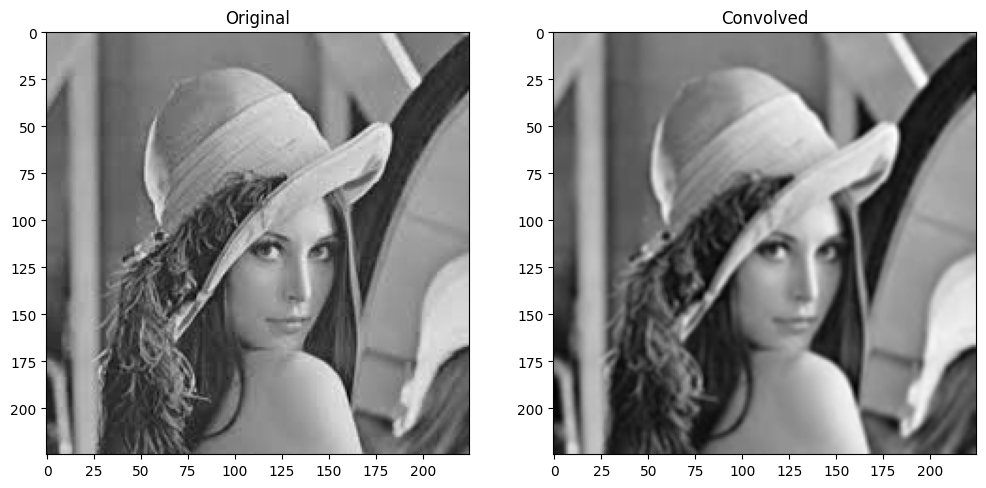

In [ ]:
# ASSIGNMENT 5
# Read the image
image = cv2.imread(images_path + 'lena.jpeg', cv2.IMREAD_GRAYSCALE)

# Define the kernel
kernel = np.array([
    [1/9, 1/9, 1/9],
    [1/9, 1/9, 1/9],
    [1/9, 1/9, 1/9]
])

# Apply convolution (note that convolution cannot return negative values using this kernel)
im_conv = cv2.filter2D(src=image, ddepth=-1, kernel=kernel)

# Show original image
plt.figure(figsize=(12,12))
plt.subplot(121)
plt.title('Original')
plt.imshow(image, cmap = "gray")

# Show convolved image
plt.subplot(122)
plt.title('Convolved')
plt.imshow(im_conv, cmap = "gray")
plt.show()

<font color='blue'>**Expected output:**  </font>

![image.png](https://raw.githubusercontent.com/jotaraul/cv_hub/refs/heads/main/image_processing/images/expected_filter.png)


### <font color="blue"><b><i>Thinking about it (2)</i></b></font>

**Answer the following questions** about convolution:

- What is the difference between the original image and the convolved one?

    <p style="margin: 4px 0px 6px 5px; color:blue"><i>Your answer here!</i></p>

- Can you guess which IP technique is such kernel implementing?

    <p style="margin: 4px 0px 6px 5px; color:blue"><i>Your answer here!</i></p>

Additionally, you can use [this demo](https://setosa.io/ev/image-kernels/) to understand the convolution operator for image processing in a visual way. Anyway, **don't worry if you don't fully understand it**, convolution is a complex operation that have multiple applications and will be understood progressively while doing practical exercises. Exciting, isn't it?

## 2.1.5 Image resizing <a id=215></a>

Resizing an image (changing its resolution) is a frequent requirement in computer vision, for example to adjust input dimensions for deep neural networks or to inspect details with zoom. It comprises two complementary operations:

- **Upsampling:** Increasing the image resolution. New pixel locations must be computed from the existing ones using **interpolation**.
- **Downsampling:** Decreasing the image resolution (reducing the sampling rate). Without proper filtering, it can produce **aliasing** (false patterns).

### A. Upsampling and interpolation

When scaling an image up, we map the new coordinate grid back to the input image (**inverse mapping**) to determine the new intensity values. The three most common interpolation methods are:

- **Nearest neighbor (`cv2.INTER_NEAREST`):** Selects the intensity of the closest pixel. It is very fast, but results in noticeable pixelation and blocky artifacts.
- **Bilinear (`cv2.INTER_LINEAR`):** Calculates a weighted average of the 4 nearest neighbors. Produces smoother transitions and is the default choice for many applications.
- **Bicubic (`cv2.INTER_CUBIC`):** Computes a weighted average of the 16 nearest neighbors using cubic polynomials. It preserves edges and fine structures better, but requires more computation.

<center><img src="https://raw.githubusercontent.com/jotaraul/cv_hub/refs/heads/main/image_processing/images/interpolation_theory.png" width="650" /></center>


### **<span style="color:green"><b><i>ASSIGNMENT 6: Comparing interpolation methods</i></b></span>**

Implement a function called `interpolation_chart()` that:
- Receives a grayscale or color image and an integer `scale_factor`.
- Computes the resized image using Nearest Neighbor, Bilinear, and Bicubic interpolation via `cv2.resize()`.
- If `verbose = True`, displays in a $1\times3$ plot the three resized versions for visual comparison.
- Returns a tuple `(nearest, bilinear, bicubic)` containing the resized images.

*Tip: in OpenCV, the function [cv2.resize()](https://docs.opencv.org/master/da/d54/group__imgproc__transform.html#ga47a974309e9102f5f08231edc7e7529d) takes `(width, height)` as the output dimension tuple (notice `width` comes first!).*


In [ ]:
# ASSIGNMENT 6
# Implement a function that:
# -- takes an image and a scale_factor
# -- computes resized versions using NEAREST, LINEAR and CUBIC interpolation
# -- displays them in a 1x3 plot if verbose = True
# -- returns (nearest, bilinear, bicubic)
def interpolation_chart(image, scale_factor=4, verbose=False):
    """ Scales an image up using different interpolation methods.

        Args:
            image: Input image
            scale_factor: Integer scaling factor
            verbose: Only show images if this is True

        Returns:
            nearest, bilinear, bicubic: Resized images
    """
    new_width = int(image.shape[1] * scale_factor)
    new_height = int(image.shape[0] * scale_factor)
    dim = (new_width, new_height)

    nearest = cv2.resize(image, dim, interpolation=cv2.INTER_NEAREST)
    bilinear = cv2.resize(image, dim, interpolation=cv2.INTER_LINEAR)
    bicubic = cv2.resize(image, dim, interpolation=cv2.INTER_CUBIC)

    if verbose:
        plt.figure(figsize=(15, 5))

        plt.subplot(1, 3, 1)
        plt.imshow(nearest, cmap='gray' if len(image.shape) == 2 else None)
        plt.title(f'Nearest Neighbor (x{scale_factor})')

        plt.subplot(1, 3, 2)
        plt.imshow(bilinear, cmap='gray' if len(image.shape) == 2 else None)
        plt.title(f'Bilinear (x{scale_factor})')

        plt.subplot(1, 3, 3)
        plt.imshow(bicubic, cmap='gray' if len(image.shape) == 2 else None)
        plt.title(f'Bicubic (x{scale_factor})')

        plt.show()

    return nearest, bilinear, bicubic


You can use the next code to **test if your results are correct**:


In [ ]:
test_matrix = np.array([[10, 50], [100, 200]], dtype=np.uint8)
nn, bl, bc = interpolation_chart(test_matrix, scale_factor=2)
print("Nearest:\n", nn)
print("Bilinear:\n", bl)
print("Bicubic:\n", bc)


Nearest:
 [[ 10  10  50  50]
 [ 10  10  50  50]
 [100 100 200 200]
 [100 100 200 200]]
Bilinear:
 [[ 10  20  40  50]
 [ 33  46  74  88]
 [ 78  99 141 163]
 [100 125 175 200]]
Bicubic:
 [[  0   8  27  38]
 [ 25  43  72  90]
 [ 70  99 146 175]
 [ 98 134 192 227]]


<font color='blue'>**Expected output:**  </font>

    Nearest:
     [[ 10  10  50  50]
      [ 10  10  50  50]
      [100 100 200 200]
      [100 100 200 200]]
    Bilinear:
     [[ 10  20  40  50]
      [ 33  46  74  88]
      [ 78  99 141 163]
      [100 125 175 200]]
    Bicubic:
     [[  0   8  27  38]
      [ 25  43  72  90]
      [ 70  99 146 175]
      [ 98 134 192 227]]


In [ ]:
# Crop a small region from the car plate to clearly inspect interpolation differences
plate_crop = image_cropped[35:75, 120:150]
nn, bl, bc = interpolation_chart(plate_crop, scale_factor=6, verbose=True)


### <font color="blue"><b><i>Thinking about it (3)</i></b></font>

Inspect the visual result obtained on the cropped plate above. Then, **answer the following questions**:

- What visual differences do you observe between the three interpolation methods? Which one looks most pixelated, and which one provides smoother edges?
  
    <p style="margin: 4px 0px 6px 5px; color:blue"><i>Your answer here!</i></p>
    
- In what practical scenario would you prefer Nearest Neighbor over Bicubic, considering both computational cost and visual quality?

    <p style="margin: 4px 0px 0px 5px; color:blue"><i>Your answer here!</i></p>


### B. Downsampling and anti-aliasing

When reducing the resolution of an image, there are two primary approaches:
1. **Decimation (direct downsampling):** Keeping only every $M$-th pixel and discarding the rest (e.g. `image[::M, ::M]`).
2. **Interpolation-based resampling:** Mapping pixel coordinates similarly to downscaling.

#### The Aliasing Problem
According to the Nyquist-Shannon sampling theorem, a signal can only be properly reconstructed if it is sampled at a frequency at least twice its highest frequency component. When an image contains fine repetitive patterns (such as fences, fabrics, or concentric rings) and we simply decimate it, those high frequencies fold into lower frequencies, creating **aliasing artifacts** (such as moiré patterns and jagged lines).

> **Key Idea:** To prevent aliasing, **smooth the image** with a low-pass filter (such as a Gaussian filter) **before downsampling**. This removes fine details that cannot be represented at the lower resolution.

<center><img src="https://raw.githubusercontent.com/jotaraul/cv_hub/refs/heads/main/image_processing/images/aliasing_theory.png" width="650" /></center>


### **<span style="color:green"><b><i>ASSIGNMENT 7: Downsampling and anti-aliasing</i></b></span>**

Implement a function called `downsample_chart()` that:
- Receives a grayscale image, a downsampling factor `step`, and a smoothing parameter `sigma`.
- Performs **direct downsampling** by decimation (taking 1 every `step` pixels).
- Performs **anti-aliased downsampling** by first smoothing the image with `cv2.GaussianBlur` using `sigmaX=sigma` and then decimating the smoothed image.
- If `verbose = True`, displays in a $1\times3$ plot: the original image, the decimated image with aliasing, and the anti-aliased image.
- Returns a tuple `(decimated, anti_aliased)`.

*Tip: you can pass `ksize=(0, 0)` to `cv2.GaussianBlur(image, (0, 0), sigmaX=sigma)` so OpenCV computes the optimal kernel size automatically from sigma.*


In [ ]:
# ASSIGNMENT 7
# Implement a function that:
# -- takes an image, a decimation step, and a gaussian sigma
# -- computes direct decimation: image[::step, ::step]
# -- computes anti-aliased decimation: smooth first with cv2.GaussianBlur, then decimate
# -- displays the comparison in a 1x3 plot if verbose = True
# -- returns (decimated, anti_aliased)
def downsample_chart(image, step=4, sigma=2.0, verbose=False):
    """ Downsamples an image with and without anti-aliasing.

        Args:
            image: Input image
            step: Decimation step (downsampling factor)
            sigma: Standard deviation for Gaussian smoothing
            verbose: Only show images if this is True

        Returns:
            decimated, anti_aliased: Downsampled images
    """
    # 1. Direct decimation
    decimated = image[::step, ::step]

    # 2. Anti-aliased downsampling (smooth before decimation)
    smoothed = cv2.GaussianBlur(image, (0, 0), sigmaX=sigma)
    anti_aliased = smoothed[::step, ::step]

    if verbose:
        plt.figure(figsize=(15, 5))

        plt.subplot(1, 3, 1)
        plt.imshow(image, cmap='gray')
        plt.title(f'Original ({image.shape[1]}x{image.shape[0]})')

        plt.subplot(1, 3, 2)
        plt.imshow(decimated, cmap='gray')
        plt.title(f'Direct Decimation (step={step})\n(Aliasing / Moiré)')

        plt.subplot(1, 3, 3)
        plt.imshow(anti_aliased, cmap='gray')
        plt.title(f'Anti-aliased (step={step})\n(Smoothed + Decimated)')

        plt.show()

    return decimated, anti_aliased


You can use the next code to **test if your results are correct**:


In [ ]:
test_matrix = np.array([[10, 20, 30, 40],
                        [50, 60, 70, 80],
                        [90, 100, 110, 120],
                        [130, 140, 150, 160]], dtype=np.uint8)
dec, aa = downsample_chart(test_matrix, step=2, sigma=1.0)
print("Decimated:\n", dec)
print("Anti-aliased:\n", aa)


Decimated:
 [[ 10  30]
 [ 90 110]]
Anti-aliased:
 [[ 46  58]
 [ 93 104]]


<font color='blue'>**Expected output:**  </font>

    Decimated:
     [[ 10  30]
      [ 90 110]]
    Anti-aliased:
     [[ 46  58]
      [ 93 104]]


In [ ]:
# Read the concentric rings pattern and interact with downsampling parameters
rings_image = cv2.imread(images_path + 'rings.png', 0)

step_slider = widgets.IntSlider(value=4, min=2, max=8, step=1, description='Step (M):')
sigma_slider = widgets.FloatSlider(value=2.0, min=0.5, max=5.0, step=0.5, description='Sigma:')

interactive(downsample_chart, image=fixed(rings_image), step=step_slider, sigma=sigma_slider, verbose=fixed(True))


### <font color="blue"><b><i>Thinking about it (4)</i></b></font>

Experiment with the sliders above using the concentric rings image. Then, **answer the following questions**:

- What kind of false patterns (Moiré effects) appear when you increase the decimation step without smoothing?
  
    <p style="margin: 4px 0px 6px 5px; color:blue"><i>Your answer here!</i></p>
    
- Why does smoothing the image before downsampling eliminate these false patterns, even if the resulting image appears slightly blurrier?

    <p style="margin: 4px 0px 0px 5px; color:blue"><i>Your answer here!</i></p>


## <font color="orange"><b><i>AI Appendix</i></b></font>

### A.1 How I used AI
- **Model/tool:**
  <p style="margin: 4px 0px 6px 5px; color:blue"><i>Your answer here!</i></p>
- **What I asked AI to help with (bullets):**
  <p style="margin: 4px 0px 6px 5px; color:blue"><i>Your answer here!</i></p>
- **Best prompt I used (paste):**
  <p style="margin: 4px 0px 6px 5px; color:blue"><i>Your answer here!</i></p>
- **What I kept vs. changed from the AI output:**
  <p style="margin: 4px 0px 6px 5px; color:blue"><i>Your answer here!</i></p>

### A.2 AI review
Ask one generative AI to review your memo using this prompt:

```
Act as a technical reviewer of this computer vision lab notebook. Read my memo and return exactly 5 bullet points:

- two on theory (key ideas),
- two on practice (relevant programming concepts of python used, not particular functions or variables),
- one on how to improve the code (most critical aspect: limitations, parameter choices, runtime/robustness, possible bugs).

Keep each bullet ≤15 words and make them specific to my work.
```

Paste its **5** items here:

- **(Theory 1)** AI claim:
  <p style="margin: 4px 0px 6px 5px; color:blue"><i>Your answer here!</i></p>
- **(Theory 2)** AI claim:
  <p style="margin: 4px 0px 6px 5px; color:blue"><i>Your answer here!</i></p>
- **(Practice 1)** AI claim:
  <p style="margin: 4px 0px 6px 5px; color:blue"><i>Your answer here!</i></p>
- **(Practice 2)** AI claim:
  <p style="margin: 4px 0px 6px 5px; color:blue"><i>Your answer here!</i></p>
- **(Improvement)** AI claim:
  <p style="margin: 4px 0px 6px 5px; color:blue"><i>Your answer here!</i></p>

Finally, **do you agree with them?**, **would you have selected others?**
    <p style="margin: 4px 0px 6px 5px; color:blue"><i>Your answer here!</i></p>

## Conclusion
Brilliant! With this notebook we have:
- Learned basic concepts within image processing like histograms, brightness, contrast, binarization and Look-up Tables.
- Played a bit with them in the context of a plate recognition system, observing their utility for improving the quality of an image according to our needs.
- Understood how convolution works.
- Explored image resizing: upsampling with different interpolation techniques (Nearest neighbor, Bilinear, Bicubic) and downsampling via decimation, understanding the phenomenon of aliasing and how anti-aliasing smoothing prevents false patterns.
